In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [11]:
# Load the dataset
df = pd.read_csv('train_20newsgroups.csv')

# Inspect basic details
print(f"Dataset Shape: {df.shape}")
print(df.head())

Dataset Shape: (10905, 3)
                                           documents  labels  \
0  I was wondering if anyone out there could enli...       7   
1  A fair number of brave souls who upgraded thei...       4   
2  well folks, my mac plus finally gave up the gh...       4   
3  Do you have Weitek's address/phone number? I'd...       1   
4  From article <C5owCB.n3p@world.std.com>, by to...      14   

             label_names  
0              rec.autos  
1  comp.sys.mac.hardware  
2  comp.sys.mac.hardware  
3          comp.graphics  
4              sci.space  


In [12]:
# Separate features and target
X = df['documents']
y = df['labels']

In [13]:
# Split into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [14]:
print(f"Training set size: {len(X_train)}")
print(f"Testing set size: {len(X_test)}")

Training set size: 8724
Testing set size: 2181


In [15]:
# Feature extraction for Multinomial NB (Term Frequencies)
mnb_vectorizer = CountVectorizer(stop_words='english', max_features=10000)
X_train_mnb = mnb_vectorizer.fit_transform(X_train)
X_test_mnb = mnb_vectorizer.transform(X_test)

# Feature extraction for Bernoulli NB (Binary Word Occurrences)
bnb_vectorizer = CountVectorizer(stop_words='english', max_features=10000, binary=True)
X_train_bnb = bnb_vectorizer.fit_transform(X_train)
X_test_bnb = bnb_vectorizer.transform(X_test)

In [16]:
# Train Multinomial Naïve Bayes
mnb = MultinomialNB()
mnb.fit(X_train_mnb, y_train)
y_pred_mnb = mnb.predict(X_test_mnb)

# Train Bernoulli Naïve Bayes
bnb = BernoulliNB()
bnb.fit(X_train_bnb, y_train)
y_pred_bnb = bnb.predict(X_test_bnb)

# Calculate performance metrics
acc_mnb = accuracy_score(y_test, y_pred_mnb)
f1_mnb = f1_score(y_test, y_pred_mnb, average='macro')

acc_bnb = accuracy_score(y_test, y_pred_bnb)
f1_bnb = f1_score(y_test, y_pred_bnb, average='macro')

# Display Comparison Summary
results_df = pd.DataFrame({
    'Model': ['Multinomial Naïve Bayes', 'Bernoulli Naïve Bayes'],
    'Accuracy': [acc_mnb, acc_bnb],
    'Macro F1-Score': [f1_mnb, f1_bnb]
})

print(results_df.to_string(index=False))

                  Model  Accuracy  Macro F1-Score
Multinomial Naïve Bayes  0.679046        0.658798
  Bernoulli Naïve Bayes  0.562586        0.567607


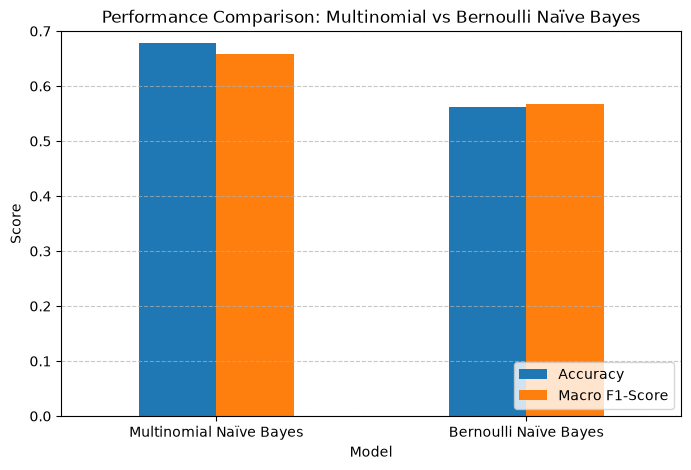

In [18]:
# Plot Accuracy and Macro F1 Comparisons
fig, ax = plt.subplots(figsize=(8, 5))
results_df.set_index('Model').plot(kind='bar', ax=ax)

plt.title('Performance Comparison: Multinomial vs Bernoulli Naïve Bayes')
plt.ylabel('Score')
plt.ylim(0, 0.70)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()